In [34]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\truths.csv"
)

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"File not found: {DATA_PATH}")

# Load original data without modifying the source file
df_raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    dtype="string",
    keep_default_na=False
)

print(f"Original records: {len(df_raw):,}")
print(f"Original columns: {df_raw.shape[1]}")

Original records: 1,051,149
Original columns: 13


## Removing Exact Duplicates

In [35]:
# Create a working copy
df_clean = df_raw.copy()

# Count exact duplicates
duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("DUPLICATE REMOVAL")
print("---------------------------")
print(f"Original records: {len(df_raw):,}")
print(f"Exact duplicates removed: {duplicates_before:,}")
print(f"Remaining records: {len(df_clean):,}")
print(f"Remaining exact duplicates: {df_clean.duplicated().sum():,}")

# Validate the result
assert df_clean.duplicated().sum() == 0

DUPLICATE REMOVAL
---------------------------
Original records: 1,051,149
Exact duplicates removed: 12,324
Remaining records: 1,038,825
Remaining exact duplicates: 0


## Converting Data Types

In [36]:
# Convert identifiers
df_clean["id"] = pd.to_numeric(
    df_clean["id"], errors="raise"
).astype("Int64")

df_clean["author"] = pd.to_numeric(
    df_clean["author"].replace("", pd.NA),
    errors="raise"
).astype("Int64")

# Convert timestamps
for col in ["timestamp", "time_scraped"]:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="ISO8601",
        errors="raise"
    )

# Convert boolean columns
boolean_mapping = {"t": True, "f": False}

for col in ["is_retruth", "is_reply"]:
    df_clean[col] = (
        df_clean[col]
        .map(boolean_mapping)
        .astype("boolean")
    )

# Convert engagement metrics
engagement_cols = [
    "like_count",
    "retruth_count",
    "reply_count"
]

for col in engagement_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="raise"
    ).astype("Int64")

print("DATA TYPES AFTER CLEANING")
print("---------------------------")
display(df_clean.dtypes)

print("\nMissing values after conversion:")
display(df_clean.isna().sum())

DATA TYPES AFTER CLEANING
---------------------------


id                          Int64
timestamp          datetime64[us]
time_scraped       datetime64[us]
is_retruth                boolean
is_reply                  boolean
author                      Int64
like_count                  Int64
retruth_count               Int64
reply_count                 Int64
text                       string
external_id                string
url                        string
truth_retruthed            string
dtype: object


Missing values after conversion:


id                   0
timestamp            0
time_scraped         0
is_retruth           0
is_reply             0
author             145
like_count           0
retruth_count        0
reply_count          0
text                 0
external_id          0
url                  0
truth_retruthed      0
dtype: int64

In [37]:
# Identify missing author IDs
missing_author_mask = (
    df_clean["author"].isna()
)

missing_authors = df_clean.loc[missing_author_mask].copy()

print("MISSING AUTHOR ANALYSIS")
print("---------------------------")
print(f"Total records: {len(df_clean):,}")
print(f"Missing authors: {len(missing_authors):,}")
print(f"Missing percentage: {missing_author_mask.mean() * 100:.4f}%")

# Inspect relevant columns
display(
    missing_authors[
        ["id", "author", "external_id", "url"]
    ].head(15)
)

MISSING AUTHOR ANALYSIS
---------------------------
Total records: 1,038,825
Missing authors: 145
Missing percentage: 0.0140%


,id,author,external_id,url
134639,895511,<NA>,truthtent,108864982160272342
134654,895527,<NA>,JackPosobiec,108822381542261053
134663,895535,<NA>,JohnPaulMacIsaac,108814846897812544
134664,895536,<NA>,Lara45,109073924301696705
134679,895573,<NA>,JackPosobiec,108639442992116282
134683,895587,<NA>,MelaniaTrump,109027164115408705
134686,895595,<NA>,NewsMax,109017355982286163
134692,895553,<NA>,DonaldJTrumpJr,108712395933363004
135661,897718,<NA>,doug4gov,109105436245928682
136412,899018,<NA>,PepeLivesMatter,107922117579592120


In [38]:
# Extract usernames from canonical Truth Social URLs
df_clean["username_from_url"] = (
    df_clean["url"]
    .astype("string")
    .str.extract(
        r"(?i)^https?://(?:www\.)?truthsocial\.com/@([^/?#]+)/posts/",
        expand=False
    )
    .str.lower()
)

# Build mappings using records with known author IDs
known_authors = df_clean[
    df_clean["author"].notna()
    & df_clean["username_from_url"].notna()
].copy()

# Count distinct authors per username
username_author_counts = (
    known_authors.groupby("username_from_url")["author"]
    .nunique()
)

# Keep only unambiguous mappings
valid_usernames = username_author_counts[
    username_author_counts == 1
].index

username_to_author = (
    known_authors[
        known_authors["username_from_url"].isin(valid_usernames)
    ]
    .groupby("username_from_url")["author"]
    .first()
)

print("USERNAME-AUTHOR MAPPING")
print("---------------------------")
print(f"Unique usernames: {len(username_author_counts):,}")
print(f"Unambiguous mappings: {len(username_to_author):,}")
print(f"Ambiguous mappings: {(username_author_counts > 1).sum():,}")

USERNAME-AUTHOR MAPPING
---------------------------
Unique usernames: 18,634
Unambiguous mappings: 18,631
Ambiguous mappings: 3


In [39]:
# Candidate username from external_id
external_username = (
    df_clean["external_id"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Consider external_id only when it looks like a username
external_username = external_username.where(
    external_username.str.fullmatch(
        r"[a-z0-9_]+",
        na=False
    )
    & external_username.str.contains(
        r"[a-z_]",
        na=False
    )
)

# Match both potential sources against known author mappings
author_from_url = (
    df_clean["username_from_url"].map(username_to_author)
)

author_from_external = (
    external_username.map(username_to_author)
)

# Detect conflicting candidates
conflicting_candidates = (
    missing_author_mask
    & author_from_url.notna()
    & author_from_external.notna()
    & author_from_url.ne(author_from_external).fillna(False)
)

# Prefer username extracted from the canonical URL
author_candidate = author_from_url.combine_first(
    author_from_external
)

# Exclude conflicting evidence
recoverable_mask = (
    missing_author_mask
    & author_candidate.notna()
    & ~conflicting_candidates
)

print("AUTHOR RECOVERY CANDIDATES")
print("---------------------------")
print(f"Missing authors: {missing_author_mask.sum():,}")
print(f"Recoverable candidates: {recoverable_mask.sum():,}")
print(f"Conflicting candidates: {conflicting_candidates.sum():,}")
print(f"Unresolved: {(missing_author_mask & ~recoverable_mask).sum():,}")

display(
    df_clean.loc[
        recoverable_mask,
        ["id", "author", "external_id", "url"]
    ].assign(
        inferred_author=author_candidate.loc[recoverable_mask]
    ).head(15)
)

AUTHOR RECOVERY CANDIDATES
---------------------------
Missing authors: 145
Recoverable candidates: 58
Conflicting candidates: 0
Unresolved: 87


,id,author,external_id,url,inferred_author
134683,895587,<NA>,MelaniaTrump,109027164115408705,559
134686,895595,<NA>,NewsMax,109017355982286163,145
134692,895553,<NA>,DonaldJTrumpJr,108712395933363004,300
136412,899018,<NA>,PepeLivesMatter,107922117579592120,1343
145236,914237,<NA>,TravisTritt,107849593147323752,206
145368,915764,<NA>,DoItPepe,109119256185776036,9596
145435,914431,<NA>,VeBo1991,108202334611281775,2477
145447,914450,<NA>,RealCarolLeek,108015702747545270,21479
145454,914456,<NA>,jkk4782,107998916362910992,7983
145480,914466,<NA>,ThePatriotVoice,107981749571692604,928


In [40]:
# Preserve information about imputed author IDs
df_clean["author_imputed"] = False

# Fill missing author IDs using validated candidates
df_clean.loc[recoverable_mask, "author"] = (
    author_candidate.loc[recoverable_mask].astype("Int64")
)

# Flag imputed records
df_clean.loc[recoverable_mask, "author_imputed"] = True

# Final validation
print("AUTHOR IMPUTATION RESULTS")
print("---------------------------")
print(f"Missing authors before: {missing_author_mask.sum():,}")
print(f"Authors recovered: {df_clean['author_imputed'].sum():,}")
print(f"Missing authors after: {df_clean['author'].isna().sum():,}")

assert (
    df_clean["author_imputed"].sum()
    + df_clean["author"].isna().sum()
    == missing_author_mask.sum()
)

AUTHOR IMPUTATION RESULTS
---------------------------
Missing authors before: 145
Authors recovered: 58
Missing authors after: 87


In [41]:
# Count supporting observations for each username-author mapping
mapping_support = (
    known_authors.groupby("username_from_url")
    .size()
)

# Get usernames used for imputations
imputed_usernames = (
    df_clean["username_from_url"]
    .combine_first(external_username)
)

# Inspect supporting evidence for recovered authors
validation_df = pd.DataFrame({
    "truth_id": df_clean.loc[df_clean["author_imputed"], "id"],
    "imputed_author": df_clean.loc[df_clean["author_imputed"], "author"],
    "username": imputed_usernames.loc[df_clean["author_imputed"]]
})

validation_df["supporting_records"] = (
    validation_df["username"]
    .map(mapping_support)
)

print("IMPUTATION VALIDATION")
print("---------------------------")

display(
    validation_df.sort_values(
        "supporting_records",
        ascending=True
    ).head(20)
)

print("\nMappings supported by one observation:",
      (validation_df["supporting_records"] == 1).sum())

IMPUTATION VALIDATION
---------------------------


,truth_id,imputed_author,username,supporting_records
145435,914431,2477,vebo1991,1
145454,914456,7983,jkk4782,1
145480,914466,928,thepatriotvoice,1
158668,938012,2081,repgregsteube,1
159769,939902,122,govrondesantis,1
160999,942084,122,govrondesantis,1
160910,941997,207,hodgetwins,1
160937,942039,122,govrondesantis,1
160988,942075,122,govrondesantis,1
161253,942434,9287,patriotflyer,1



Mappings supported by one observation: 11


In [42]:
# Identify the exact username used for each imputation
actual_imputation_username = (
    df_clean["username_from_url"]
    .where(author_from_url.notna())
    .combine_first(
        external_username.where(author_from_external.notna())
    )
)

# Reconstruct the author from the actual mapping
validated_author = actual_imputation_username.map(
    username_to_author
)

# Verify imputed author IDs
imputation_matches = (
    df_clean.loc[df_clean["author_imputed"], "author"]
    .eq(validated_author.loc[df_clean["author_imputed"]])
)

print("IMPUTATION CONSISTENCY CHECK")
print("---------------------------")
print(f"Imputed authors: {df_clean['author_imputed'].sum()}")
print(f"Consistent imputations: {imputation_matches.sum()}")
print(f"Inconsistent imputations: {(~imputation_matches).sum()}")

IMPUTATION CONSISTENCY CHECK
---------------------------
Imputed authors: 58
Consistent imputations: 58
Inconsistent imputations: 0


In [43]:
from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd

# Define the path to users.xml
USERS_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\users.xml"
)

if not USERS_PATH.is_file():
    raise FileNotFoundError(f"File not found: {USERS_PATH}")

# Parse the XML file
tree = ET.parse(USERS_PATH)
root = tree.getroot()

print("USERS.XML STRUCTURE")
print("---------------------------")
print("Root tag:", root.tag)
print("Number of direct child elements:", len(root))

# Inspect the first user records
for user in list(root)[:3]:
    print("\nUser tag:", user.tag)
    print("Attributes:", user.attrib)

    for child in user:
        print(f"  {child.tag}: {child.text}")

USERS.XML STRUCTURE
---------------------------
Root tag: data
Number of direct child elements: 487292

User tag: row
Attributes: {}
  id_user: 1238
  timestamp_user_creation: 2022-02-01 00:00:00
  username: jeffgolfs
  follower_count: 886
  following_count: 204
  profile_url: https://truthsocial.com/@jeffgolfs
  finished_follower_scrape: f
  finished_following_scrape: f
  finished_truth_scrape: f

User tag: row
Attributes: {}
  id_user: 50
  timestamp_user_creation: 2022-02-01 00:00:00
  username: MizW
  follower_count: 2365
  following_count: 2929
  profile_url: https://truthsocial.com/@MizW
  finished_follower_scrape: f
  finished_following_scrape: f
  finished_truth_scrape: f

User tag: row
Attributes: {}
  id_user: 6951
  timestamp_user_creation: 2022-02-01 00:00:00
  username: SusanCreech
  follower_count: 870
  following_count: 1232
  profile_url: https://truthsocial.com/@SusanCreech
  finished_follower_scrape: f
  finished_following_scrape: f
  finished_truth_scrape: f


In [44]:
# Extract relevant fields from users.xml
users_records = []

for user in root.findall("row"):
    users_records.append({
        "id_user": user.findtext("id_user"),
        "username": user.findtext("username")
    })

users_df = pd.DataFrame(users_records)

# Normalize usernames
users_df["username_clean"] = (
    users_df["username"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert user IDs to numeric
users_df["id_user"] = pd.to_numeric(
    users_df["id_user"],
    errors="coerce"
).astype("Int64")

# Remove incomplete records
users_valid = users_df.dropna(
    subset=["username_clean", "id_user"]
).copy()

users_valid = users_valid[
    users_valid["username_clean"].ne("")
]

# Identify unambiguous username-to-ID mappings
username_counts = (
    users_valid.groupby("username_clean")["id_user"]
    .nunique()
)

valid_usernames = username_counts[
    username_counts == 1
].index

users_mapping = (
    users_valid[
        users_valid["username_clean"].isin(valid_usernames)
    ]
    .groupby("username_clean")["id_user"]
    .first()
)

print("USERS.XML MAPPING")
print("---------------------------")
print(f"Total users: {len(users_df):,}")
print(f"Valid username mappings: {len(users_mapping):,}")
print(f"Ambiguous usernames: {(username_counts > 1).sum():,}")

USERS.XML MAPPING
---------------------------
Total users: 487,292
Valid username mappings: 487,068
Ambiguous usernames: 80


In [45]:
# Extract username candidates from existing columns
username_from_external = (
    df_clean["external_id"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Select username from URL when available,
# otherwise use external_id
username_candidate = (
    df_clean["username_from_url"]
    .combine_first(username_from_external)
)

# Retrieve author IDs from users.xml
author_from_users = username_candidate.map(users_mapping)

# Check previously imputed authors
previously_imputed = df_clean["author_imputed"]

validation = pd.DataFrame({
    "author_imputed": df_clean.loc[previously_imputed, "author"],
    "author_users_xml": author_from_users.loc[previously_imputed]
})

confirmed = (
    validation["author_users_xml"].notna()
    & validation["author_imputed"].eq(
        validation["author_users_xml"]
    ).fillna(False)
)

conflicting = (
    validation["author_users_xml"].notna()
    & validation["author_imputed"].ne(
        validation["author_users_xml"]
    ).fillna(False)
)

print("PREVIOUS IMPUTATION VALIDATION")
print("---------------------------")
print(f"Previously imputed: {len(validation):,}")
print(f"Confirmed by users.xml: {confirmed.sum():,}")
print(f"Conflicting mappings: {conflicting.sum():,}")
print(f"Not found in users.xml: {validation['author_users_xml'].isna().sum():,}")

display(validation.head(15))

PREVIOUS IMPUTATION VALIDATION
---------------------------
Previously imputed: 58
Confirmed by users.xml: 58
Conflicting mappings: 0
Not found in users.xml: 0


,author_imputed,author_users_xml
134683,559,559
134686,145,145
134692,300,300
136412,1343,1343
145236,206,206
145368,9596,9596
145435,2477,2477
145447,21479,21479
145454,7983,7983
145480,928,928


In [46]:
# Identify remaining missing authors
still_missing = df_clean["author"].isna()

# Find recoverable authors using users.xml
recoverable_from_users = (
    still_missing
    & author_from_users.notna()
)

print("CROSS-DATASET AUTHOR RECOVERY")
print("---------------------------")
print(f"Missing authors before: {still_missing.sum():,}")
print(f"Recoverable from users.xml: {recoverable_from_users.sum():,}")
print(f"Still unresolved: {(still_missing & ~recoverable_from_users).sum():,}")

# Inspect candidate matches before applying changes
display(
    df_clean.loc[
        recoverable_from_users,
        ["id", "external_id", "url", "author"]
    ].assign(
        inferred_author=author_from_users.loc[recoverable_from_users]
    ).head(20)
)

CROSS-DATASET AUTHOR RECOVERY
---------------------------
Missing authors before: 87
Recoverable from users.xml: 87
Still unresolved: 0


,id,external_id,url,author,inferred_author
134639,895511,truthtent,108864982160272342,<NA>,11214
134654,895527,JackPosobiec,108822381542261053,<NA>,143
134663,895535,JohnPaulMacIsaac,108814846897812544,<NA>,2098
134664,895536,Lara45,109073924301696705,<NA>,933
134679,895573,JackPosobiec,108639442992116282,<NA>,143
135661,897718,doug4gov,109105436245928682,<NA>,1413
145137,914125,Elajane,107943822372142377,<NA>,4817
145149,914135,sweetwatergirl,107924695598414362,<NA>,17391
145153,914148,xGoldylocsx,107911657290583986,<NA>,8032
145229,914225,DavidKirkland,107918278278888247,<NA>,40850


In [47]:
# Track which authors were recovered using users.xml
df_clean["author_imputed_users"] = False

# Fill remaining missing author IDs
df_clean.loc[recoverable_from_users, "author"] = (
    author_from_users.loc[recoverable_from_users]
    .astype("Int64")
)

# Mark recovered records
df_clean.loc[recoverable_from_users, "author_imputed_users"] = True

print("FINAL AUTHOR RECOVERY RESULTS")
print("---------------------------")
print(f"Recovered using truths.csv: {df_clean['author_imputed'].sum():,}")
print(f"Recovered using users.xml: {df_clean['author_imputed_users'].sum():,}")
print(f"Total recovered: {(df_clean['author_imputed'] | df_clean['author_imputed_users']).sum():,}")
print(f"Missing authors remaining: {df_clean['author'].isna().sum():,}")

FINAL AUTHOR RECOVERY RESULTS
---------------------------
Recovered using truths.csv: 58
Recovered using users.xml: 87
Total recovered: 145
Missing authors remaining: 0


## Handling Text Problems - MV and <

In [48]:
# Identify missing and malformed text values
text_series = df_clean["text"].astype("string")

# Empty or missing text
missing_text_mask = (
    text_series.isna()
    | text_series.str.strip().eq("")
)

# Text containing only "<"
less_than_mask = (
    text_series.str.strip().eq("<")
)

# Combined problematic records
problematic_text_mask = (
    missing_text_mask | less_than_mask
).fillna(False)

print("TEXT DATA QUALITY ANALYSIS")
print("---------------------------")
print(f"Total Truths: {len(df_clean):,}")
print(f"Missing/empty text: {missing_text_mask.sum():,}")
print(f"Text containing only '<': {less_than_mask.sum():,}")
print(f"Total problematic texts: {problematic_text_mask.sum():,}")
print(f"Percentage affected: {problematic_text_mask.mean() * 100:.2f}%")

# Inspect problematic records
display(
    df_clean.loc[
        problematic_text_mask,
        ["id", "external_id", "url", "author",
         "is_retruth", "is_reply", "text"]
    ].head(20)
)

TEXT DATA QUALITY ANALYSIS
---------------------------
Total Truths: 1,038,825
Missing/empty text: 176
Text containing only '<': 5,423
Total problematic texts: 5,599
Percentage affected: 0.54%


,id,external_id,url,author,is_retruth,is_reply,text
1167,807655,CeceBloomwood,107925568586381393,20054,True,False,
1193,704620,PadingtonRose,108442301408485705,11225,True,False,<
1227,704633,PadingtonRose,108434546171751458,11225,True,False,<
1244,804752,marknicholson,109104919259283807,20030,False,False,
1263,807647,CeceBloomwood,107959581599419915,20054,True,False,
10026,713325,pandyls,108241213535601948,16161,True,False,<
10045,713386,pandyls,108205161088669367,16161,True,False,<
10052,805569,marknicholson,108244712793725159,20030,True,True,
15831,720084,J6_Insurrectionist,108776517385844471,16733,True,False,<
15842,720115,PatriotAR,108642821558716084,8017,True,False,<


In [49]:
# Identify records with usable text
valid_text_mask = (
    ~problematic_text_mask
)

# Count distinct valid texts for each Truth ID
valid_text_counts = (
    df_clean.loc[valid_text_mask]
    .groupby("id")["text"]
    .nunique()
)

# Only retain IDs associated with exactly one valid text
unambiguous_ids = valid_text_counts[
    valid_text_counts == 1
].index

# Build an ID-to-text mapping
text_mapping = (
    df_clean.loc[
        valid_text_mask
        & df_clean["id"].isin(unambiguous_ids)
    ]
    .groupby("id")["text"]
    .first()
)

# Find recovery candidates
recovered_text_candidates = df_clean["id"].map(
    text_mapping
)

recoverable_text_mask = (
    problematic_text_mask
    & recovered_text_candidates.notna()
)

print("INTERNAL TEXT RECOVERY")
print("---------------------------")
print(f"Problematic texts: {problematic_text_mask.sum():,}")
print(f"Recoverable from the same Truth ID: {recoverable_text_mask.sum():,}")
print(f"Still unresolved: {(problematic_text_mask & ~recoverable_text_mask).sum():,}")

display(
    df_clean.loc[
        recoverable_text_mask,
        ["id", "text"]
    ].assign(
        recovered_text=recovered_text_candidates.loc[
            recoverable_text_mask
        ]
    ).head(10)
)

INTERNAL TEXT RECOVERY
---------------------------
Problematic texts: 5,599
Recoverable from the same Truth ID: 0
Still unresolved: 5,599


,id,text,recovered_text


In [50]:
from pathlib import Path

ARFF_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Additional_Data\additional_truths.arff"
)

if not ARFF_PATH.is_file():
    raise FileNotFoundError(f"File not found: {ARFF_PATH}")

print("ADDITIONAL TRUTHS ARFF STRUCTURE")
print("--------------------------------")

with open(ARFF_PATH, "r", encoding="utf-8-sig") as file:
    for line in file:
        line = line.strip()

        if line.lower() == "@data":
            break

        if line and not line.startswith("%"):
            print(line)

ADDITIONAL TRUTHS ARFF STRUCTURE
--------------------------------
@relation trump_truths
@attribute id integer
@attribute timestamp string
@attribute text string
@attribute url string
@attribute reply_count real
@attribute retruth_count real
@attribute like_count real
@attribute external_id string
@attribute author real
@attribute time_scraped string


In [51]:
#%pip install scipy

In [52]:
#%pip install liac-arff

In [53]:
from pathlib import Path
import pandas as pd
import arff
import re

ARFF_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Additional_Data\additional_truths.arff"
)

if not ARFF_PATH.is_file():
    raise FileNotFoundError(f"File not found: {ARFF_PATH}")

# Read ARFF content without modifying the original file
with open(ARFF_PATH, "r", encoding="utf-8-sig") as file:
    arff_content = file.read()

# Escape unsupported \x sequences for the ARFF parser
arff_content_clean = re.sub(
    r"(?<!\\)\\x",
    lambda match: "\\\\x",
    arff_content
)

# Parse ARFF content
arff_data = arff.loads(arff_content_clean)

# Convert to DataFrame
column_names = [
    attribute[0]
    for attribute in arff_data["attributes"]
]

additional_df = pd.DataFrame(
    arff_data["data"],
    columns=column_names
)

print("ADDITIONAL TRUTHS DATASET")
print("---------------------------")
print(f"Total records: {len(additional_df):,}")
print(f"Columns: {additional_df.shape[1]}")

display(additional_df.head())
display(additional_df.dtypes)

ADDITIONAL TRUTHS DATASET
---------------------------
Total records: 35,222
Columns: 10


,id,timestamp,text,url,reply_count,retruth_count,like_count,external_id,author,time_scraped
0,117323511508375200,2026-09-24 01:51:54,,https://truthsocial.com/@realDonaldTrump/11732...,792.0,1849.0,7259.0,117323511508375196,27.0,2026-09-20 14:00:00.000000
1,117323155721195616,2026-09-24 00:21:25,"The story that the White House, or me, want to...",https://truthsocial.com/@realDonaldTrump/11732...,1329.0,3534.0,12560.0,117323155721195611,27.0,2026-09-20 14:00:00.000000
2,117323148147220272,2026-09-24 00:19:29,BIG DAY FOR BOEING AND AMERICAN MANUFACTURING!...,https://truthsocial.com/@realDonaldTrump/11732...,510.0,2714.0,10677.0,117323148147220269,27.0,2026-09-20 14:00:00.000000
3,117322092055919840,2026-09-23 19:50:55,,https://truthsocial.com/@realDonaldTrump/11732...,1344.0,2740.0,11287.0,117322092055919832,27.0,2026-09-20 14:00:00.000000
4,117322065119445872,2026-09-23 19:44:04,"The Great Gary Player, Bryson DeChambeau, Mika...",https://truthsocial.com/@realDonaldTrump/11732...,505.0,2156.0,10284.0,117322065119445871,27.0,2026-09-20 14:00:00.000000


id                 int64
timestamp            str
text                 str
url                  str
reply_count      float64
retruth_count    float64
like_count       float64
external_id          str
author           float64
time_scraped         str
dtype: object

In [54]:
print("Unique IDs:", additional_df["id"].nunique())
print("Missing texts:", additional_df["text"].isna().sum())
print("Total records:", len(additional_df))

Unique IDs: 35221
Missing texts: 0
Total records: 35222


In [55]:
# Normalize ARFF IDs
additional_df["id"] = pd.to_numeric(
    additional_df["id"],
    errors="coerce"
).astype("Int64")

# Check text quality in the ARFF dataset
arff_text = additional_df["text"].astype("string")

valid_arff_text = (
    arff_text.notna()
    & arff_text.str.strip().ne("")
    & arff_text.str.strip().ne("<")
).fillna(False)

print("ARFF TEXT QUALITY")
print("---------------------------")
print(f"Total records: {len(additional_df):,}")
print(f"Usable texts: {valid_arff_text.sum():,}")
print(f"Problematic texts: {(~valid_arff_text).sum():,}")

# Compare IDs between datasets
problematic_ids = set(
    df_clean.loc[problematic_text_mask, "id"].dropna()
)

additional_ids = set(additional_df["id"].dropna())

matching_ids = problematic_ids & additional_ids

print("\nARFF TEXT RECOVERY ANALYSIS")
print("---------------------------")
print(f"Problematic Truths: {len(problematic_ids):,}")
print(f"Matching Truth IDs: {len(matching_ids):,}")
print(f"Unmatched Truth IDs: {len(problematic_ids - additional_ids):,}")

# Inspect matching records
comparison = df_clean.loc[
    problematic_text_mask,
    ["id", "author", "external_id", "url", "text"]
].merge(
    additional_df.loc[
        additional_df["id"].isin(matching_ids) & valid_arff_text,
        ["id", "author", "external_id", "url", "text"]
    ],
    on="id",
    how="inner",
    suffixes=("_original", "_arff")
)

print(f"\nPotential recovery candidates: {len(comparison):,}")

display(comparison.head(10))

ARFF TEXT QUALITY
---------------------------
Total records: 35,222
Usable texts: 27,960
Problematic texts: 7,262

ARFF TEXT RECOVERY ANALYSIS
---------------------------
Problematic Truths: 5,599
Matching Truth IDs: 0
Unmatched Truth IDs: 5,599

Potential recovery candidates: 0


,id,author_original,external_id_original,url_original,text_original,author_arff,external_id_arff,url_arff,text_arff


In [56]:
print("TRUTHS.CSV IDENTIFIERS")
print("---------------------------")

display(
    df_clean.loc[
        problematic_text_mask,
        ["id", "external_id", "url", "text"]
    ].head(10)
)

print("\nARFF IDENTIFIERS")
print("---------------------------")

display(
    additional_df[
        ["id", "external_id", "url", "text"]
    ].head(10)
)

TRUTHS.CSV IDENTIFIERS
---------------------------


,id,external_id,url,text
1167,807655,CeceBloomwood,107925568586381393,
1193,704620,PadingtonRose,108442301408485705,<
1227,704633,PadingtonRose,108434546171751458,<
1244,804752,marknicholson,109104919259283807,
1263,807647,CeceBloomwood,107959581599419915,
10026,713325,pandyls,108241213535601948,<
10045,713386,pandyls,108205161088669367,<
10052,805569,marknicholson,108244712793725159,
15831,720084,J6_Insurrectionist,108776517385844471,<
15842,720115,PatriotAR,108642821558716084,<



ARFF IDENTIFIERS
---------------------------


,id,external_id,url,text
0,117323511508375200,117323511508375196,https://truthsocial.com/@realDonaldTrump/11732...,
1,117323155721195616,117323155721195611,https://truthsocial.com/@realDonaldTrump/11732...,"The story that the White House, or me, want to..."
2,117323148147220272,117323148147220269,https://truthsocial.com/@realDonaldTrump/11732...,BIG DAY FOR BOEING AND AMERICAN MANUFACTURING!...
3,117322092055919840,117322092055919832,https://truthsocial.com/@realDonaldTrump/11732...,
4,117322065119445872,117322065119445871,https://truthsocial.com/@realDonaldTrump/11732...,"The Great Gary Player, Bryson DeChambeau, Mika..."
5,117320581360547088,117320581360547091,https://truthsocial.com/@realDonaldTrump/11732...,Victor Davis Hanson on Canada — A MUST SEE! Pr...
6,117320509296515184,117320509296515188,https://truthsocial.com/@realDonaldTrump/11732...,Canada is destroying itself by allowing millio...
7,117320385350427392,117320385350427395,https://truthsocial.com/@realDonaldTrump/11732...,Thank you to the Great Robert Greenway and Jes...
8,117318371569831040,117318371569831036,https://truthsocial.com/@realDonaldTrump/11731...,Ruddy: 'A Rising Trump Lifts All Boats': https...
9,117318370203435200,117318370203435194,https://truthsocial.com/@realDonaldTrump/11731...,Azerbaijan's Hajiyev to Newsmax: Trump Peacema...


In [57]:
import re

def extract_post_id(value):
    if pd.isna(value):
        return pd.NA

    value = str(value).strip()

    # Numeric post identifier
    if re.fullmatch(r"\d+", value):
        return value

    # Truth Social post URL
    match = re.search(
        r"truthsocial\.com/@[^/]+/posts/(\d+)",
        value,
        flags=re.IGNORECASE
    )

    if match:
        return match.group(1)

    return pd.NA


# Extract post IDs from both datasets
df_clean["post_id"] = (
    df_clean["url"].map(extract_post_id).astype("string")
)

additional_df["post_id"] = (
    additional_df["url"].map(extract_post_id).astype("string")
)

# Compare problematic Truth post IDs with ARFF post IDs
problematic_post_ids = set(
    df_clean.loc[
        problematic_text_mask, "post_id"
    ].dropna()
)

arff_post_ids = set(
    additional_df["post_id"].dropna()
)

matching_post_ids = problematic_post_ids & arff_post_ids

print("POST ID MATCHING ANALYSIS")
print("---------------------------")
print(f"Problematic Truth post IDs: {len(problematic_post_ids):,}")
print(f"ARFF post IDs: {len(arff_post_ids):,}")
print(f"Matching post IDs: {len(matching_post_ids):,}")

POST ID MATCHING ANALYSIS
---------------------------
Problematic Truth post IDs: 4,417
ARFF post IDs: 0
Matching post IDs: 0


In [58]:
print("ARFF IDENTIFIER INSPECTION")
print("---------------------------")

# Display identifiers from the ARFF dataset
display(
    additional_df[
        ["id", "external_id", "url", "author"]
    ].head(20)
)

# Count numeric values in each column
for col in ["external_id", "url"]:

    values = additional_df[col].astype("string").str.strip()

    numeric_count = values.str.fullmatch(
        r"\d+", na=False
    ).sum()

    canonical_url_count = values.str.contains(
        r"truthsocial\.com",
        case=False,
        na=False
    ).sum()

    print(f"\nColumn: {col}")
    print(f"Numeric values: {numeric_count:,}")
    print(f"Truth Social URLs: {canonical_url_count:,}")
    print(f"Unique values: {values.nunique():,}")

ARFF IDENTIFIER INSPECTION
---------------------------


,id,external_id,url,author
0,117323511508375200,117323511508375196,https://truthsocial.com/@realDonaldTrump/11732...,27.0
1,117323155721195616,117323155721195611,https://truthsocial.com/@realDonaldTrump/11732...,27.0
2,117323148147220272,117323148147220269,https://truthsocial.com/@realDonaldTrump/11732...,27.0
3,117322092055919840,117322092055919832,https://truthsocial.com/@realDonaldTrump/11732...,27.0
4,117322065119445872,117322065119445871,https://truthsocial.com/@realDonaldTrump/11732...,27.0
5,117320581360547088,117320581360547091,https://truthsocial.com/@realDonaldTrump/11732...,27.0
6,117320509296515184,117320509296515188,https://truthsocial.com/@realDonaldTrump/11732...,27.0
7,117320385350427392,117320385350427395,https://truthsocial.com/@realDonaldTrump/11732...,27.0
8,117318371569831040,117318371569831036,https://truthsocial.com/@realDonaldTrump/11731...,27.0
9,117318370203435200,117318370203435194,https://truthsocial.com/@realDonaldTrump/11731...,27.0



Column: external_id
Numeric values: 35,222
Truth Social URLs: 0
Unique values: 35,222

Column: url
Numeric values: 0
Truth Social URLs: 35,222
Unique values: 35,222


In [59]:
# Normalize post identifiers as strings
arff_post_ids = (
    additional_df["external_id"]
    .astype("string")
    .str.strip()
)

# Use post IDs previously extracted from truths.csv
truth_post_ids = (
    df_clean["post_id"]
    .astype("string")
    .str.strip()
)

# Compare problematic Truths with ARFF records
problematic_post_ids = set(
    truth_post_ids.loc[problematic_text_mask].dropna()
)

additional_post_ids = set(arff_post_ids.dropna())

matching_post_ids = (
    problematic_post_ids & additional_post_ids
)

print("CROSS-DATASET POST ID MATCHING")
print("--------------------------------")
print(f"Problematic Truth post IDs: {len(problematic_post_ids):,}")
print(f"ARFF post IDs: {len(additional_post_ids):,}")
print(f"Matching post IDs: {len(matching_post_ids):,}")

# Identify candidate ARFF records with usable text
recovery_candidates = additional_df.loc[
    arff_post_ids.isin(matching_post_ids)
    & valid_arff_text
].copy()

print(f"Potential records with usable text: {len(recovery_candidates):,}")

display(
    recovery_candidates[
        ["id", "external_id", "url", "text"]
    ].head(10)
)

CROSS-DATASET POST ID MATCHING
--------------------------------
Problematic Truth post IDs: 4,417
ARFF post IDs: 35,222
Matching post IDs: 13
Potential records with usable text: 10


,id,external_id,url,text
34298,109111035929718448,109111035929718455,https://truthsocial.com/@realDonaldTrump/10911...,RT @loudobbsRobert Jeffress joins us on #TheGr...
34318,109102004910960720,109102004910960727,https://truthsocial.com/@realDonaldTrump/10910...,https://www.aa.com.tr/en/americas/trump-calls-...
34397,109082720069591440,109082720069591446,https://truthsocial.com/@realDonaldTrump/10908...,“A former president can keep whatever presiden...
34399,109082626904067504,109082626904067503,https://truthsocial.com/@realDonaldTrump/10908...,RT @realDonaldTrumpThis is the real story on t...
34414,109074021311022832,109074021311022825,https://truthsocial.com/@realDonaldTrump/10907...,RT: https://truthsocial.com/users/KickDreaming...
34443,109067943225951888,109067943225951882,https://truthsocial.com/@realDonaldTrump/10906...,https://www.breitbart.com/entertainment/2022/0...
34481,109054369938394272,109054369938394267,https://truthsocial.com/@realDonaldTrump/10905...,"“Exclusive — Tom Homan: If Trump Wins, Many ‘P..."
34499,109048404143018336,109048404143018341,https://truthsocial.com/@realDonaldTrump/10904...,“FBI hero paying the price for exposing unjust...
34591,109027164115408704,109027164115408705,https://truthsocial.com/@realDonaldTrump/10902...,RT @MelaniaTrumpRIP Her Majesty Queen Elizabet...
34617,109017355982286160,109017355982286163,https://truthsocial.com/@realDonaldTrump/10901...,RT @NewsMaxJUST IN: Former President Donald Tr...


In [60]:
from pathlib import Path
import pandas as pd

MEDIA_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\media.json"
)

media_df = pd.read_json(MEDIA_PATH)

# Compare Truth IDs as numeric identifiers
media_truth_ids = set(
    pd.to_numeric(
        media_df["truth_id"], errors="coerce"
    ).dropna()
)

problematic_with_media = (
    df_clean.loc[problematic_text_mask, "id"]
    .isin(media_truth_ids)
)

print("PROBLEMATIC TEXTS AND MEDIA")
print("---------------------------")
print(f"Total problematic texts: {problematic_text_mask.sum():,}")
print(f"Associated with media: {problematic_with_media.sum():,}")
print(f"Without media association: {(~problematic_with_media).sum():,}")

PROBLEMATIC TEXTS AND MEDIA
---------------------------
Total problematic texts: 5,599
Associated with media: 1,544
Without media association: 4,055


In [61]:
import pandas as pd
import html

# Preserve original text
original_text = df_clean["text"].astype("string")

# Normalize HTML entities without overwriting the source
df_clean["text_clean"] = original_text.map(
    lambda x: html.unescape(x) if pd.notna(x) else pd.NA
).astype("string")

# Identify problematic texts
empty_mask = (
    original_text.isna()
    | original_text.str.strip().eq("")
).fillna(False)

malformed_mask = (
    original_text.str.strip().eq("<")
).fillna(False)

# Classify text quality
df_clean["text_quality_status"] = "valid"

df_clean.loc[
    empty_mask, "text_quality_status"
] = "empty"

df_clean.loc[
    malformed_mask, "text_quality_status"
] = "malformed"

# Replace unusable content with missing values
df_clean.loc[
    empty_mask | malformed_mask,
    "text_clean"
] = pd.NA

print("TEXT CLEANING RESULTS")
print("---------------------------")
print("Text quality distribution:")
display(df_clean["text_quality_status"].value_counts())

print("\nMissing values in text_clean:",
      df_clean["text_clean"].isna().sum())

print("\nOriginal text preserved:",
      df_clean["text"].equals(original_text))

TEXT CLEANING RESULTS
---------------------------
Text quality distribution:


text_quality_status
valid        1033226
malformed       5423
empty            176
Name: count, dtype: int64


Missing values in text_clean: 5599

Original text preserved: True


In [62]:
# Identify Truths associated with media
df_clean["has_media"] = (
    df_clean["id"].isin(media_truth_ids)
)

# Combine text quality with media availability
text_media_summary = pd.crosstab(
    df_clean["text_quality_status"],
    df_clean["has_media"]
)

print("TEXT QUALITY VS MEDIA")
print("---------------------------")

display(text_media_summary)

TEXT QUALITY VS MEDIA
---------------------------


has_media,False,True
text_quality_status,,
empty,129,47
malformed,3926,1497
valid,896921,136305


In [63]:
# Verify the number of problematic texts
assert (
    df_clean["text_quality_status"].isin(
        ["empty", "malformed"]
    ).sum() == 5599
)

# Verify that unusable texts are missing in text_clean
assert df_clean.loc[
    df_clean["text_quality_status"].isin(
        ["empty", "malformed"]
    ),
    "text_clean"
].isna().all()

# Verify that valid texts remain available
assert df_clean.loc[
    df_clean["text_quality_status"] == "valid",
    "text_clean"
].notna().all()

print("Text cleaning validation passed.")

Text cleaning validation passed.


In [64]:
# Final text cleaning validation
problematic_status = df_clean["text_quality_status"].isin(
    ["empty", "malformed"]
)

assert (
    df_clean.loc[problematic_status, "text_clean"]
    .isna().all()
)

assert (
    df_clean.loc[~problematic_status, "text_clean"]
    .notna().all()
)

assert (
    problematic_status.sum()
    == df_clean["text_clean"].isna().sum()
)

print("TEXT CLEANING VALIDATION")
print("---------------------------")
print("All checks passed.")
print(f"Usable texts: {df_clean['text_clean'].notna().sum():,}")
print(f"Unusable texts: {df_clean['text_clean'].isna().sum():,}")

TEXT CLEANING VALIDATION
---------------------------
All checks passed.
Usable texts: 1,033,226
Unusable texts: 5,599


## Is_retruthed, Truth_retruthed treating

In [66]:

# Preserve original retruth references
retruthed_raw = (
    df_clean["truth_retruthed"]
    .astype("string")
    .str.strip()
)

# Identify missing or empty references
missing_reference = (
    retruthed_raw.isna()
    | retruthed_raw.eq("")
).fillna(False)

# Identify numeric references
numeric_reference = (
    retruthed_raw.str.fullmatch(
        r"\d+",
        na=False
    )
)

# Identify other formats
other_reference = (
    ~missing_reference
    & ~numeric_reference
)

# Check consistency with is_retruth
is_retruth = df_clean["is_retruth"].fillna(False)

print("RETRUTH DATA QUALITY ASSESSMENT")
print("--------------------------------")
print(f"Total Truths: {len(df_clean):,}")
print(f"Retruths: {is_retruth.sum():,}")
print(f"Original Truths: {(~is_retruth).sum():,}")

print("\nREFERENCE FORMATS")
print("--------------------------------")
print(f"Missing/empty references: {missing_reference.sum():,}")
print(f"Numeric references: {numeric_reference.sum():,}")
print(f"Other formats: {other_reference.sum():,}")

print("\nCONSISTENCY CHECK")
print("--------------------------------")
print(
    "Retruths without numeric reference:",
    (is_retruth & ~numeric_reference).sum()
)
print(
    "Non-retruths with numeric reference:",
    (~is_retruth & numeric_reference).sum()
)

# Inspect unexpected reference formats
display(
    df_clean.loc[
        other_reference,
        ["id", "is_retruth", "truth_retruthed"]
    ].head(20)
)

RETRUTH DATA QUALITY ASSESSMENT
--------------------------------
Total Truths: 1,038,825
Retruths: 246,082
Original Truths: 792,743

REFERENCE FORMATS
--------------------------------
Missing/empty references: 277,911
Numeric references: 0
Other formats: 760,914

CONSISTENCY CHECK
--------------------------------
Retruths without numeric reference: 246082
Non-retruths with numeric reference: 0


,id,is_retruth,truth_retruthed
0,703265,True,1043583.0
1,807614,True,988567.0
2,807615,True,1002825.0
3,807618,True,989757.0
4,807619,False,-1.0
5,807621,True,982887.0
6,807622,True,985286.0
7,807624,True,988984.0
8,807625,True,1002928.0
9,703272,False,-1.0


In [67]:

# Preserve original retruth references
raw_reference = (
    df_clean["truth_retruthed"]
    .astype("string")
    .str.strip()
)

# Normalize numeric references stored with decimal suffix
normalized_reference = raw_reference.str.replace(
    r"\.0$",
    "",
    regex=True
)

# Convert references to numeric identifiers
numeric_reference = pd.to_numeric(
    normalized_reference,
    errors="coerce"
).astype("Int64")

# Treat 0 and -1 as missing/sentinel values
df_clean["truth_retruthed_clean"] = (
    numeric_reference.where(numeric_reference > 0, pd.NA)
)

# Identify valid reference formats
valid_reference = df_clean["truth_retruthed_clean"].notna()

# Check whether references point to existing internal Truth IDs
known_truth_ids = set(df_clean["id"].dropna())

target_present = (
    df_clean["truth_retruthed_clean"]
    .isin(known_truth_ids)
)

# Identify self-references
self_reference = (
    df_clean["id"]
    .eq(df_clean["truth_retruthed_clean"])
    .fillna(False)
)

# Classify reference quality
df_clean["retruthed_reference_status"] = "not_retruth"

is_retruth = df_clean["is_retruth"].fillna(False)

df_clean.loc[
    is_retruth & ~valid_reference,
    "retruthed_reference_status"
] = "missing_reference"

df_clean.loc[
    is_retruth & valid_reference & ~target_present,
    "retruthed_reference_status"
] = "target_absent"

df_clean.loc[
    is_retruth & valid_reference & target_present,
    "retruthed_reference_status"
] = "resolved"

df_clean.loc[
    is_retruth & self_reference,
    "retruthed_reference_status"
] = "self_reference"

# Flag unexpected references in non-retruth records
df_clean.loc[
    ~is_retruth & valid_reference,
    "retruthed_reference_status"
] = "inconsistent_non_retruth"

print("RETRUTH REFERENCE CLEANING")
print("---------------------------")

display(
    df_clean["retruthed_reference_status"]
    .value_counts()
)

print("\nMissing normalized references:",
      df_clean["truth_retruthed_clean"].isna().sum())

print("\nOriginal references preserved:",
      "truth_retruthed" in df_clean.columns)

RETRUTH REFERENCE CLEANING
---------------------------


retruthed_reference_status
not_retruth                 792742
target_absent               153628
resolved                     79494
missing_reference             6827
self_reference                6133
inconsistent_non_retruth         1
Name: count, dtype: int64


Missing normalized references: 799569

Original references preserved: True


In [68]:
# Validate retruth reference cleaning
status = df_clean["retruthed_reference_status"]
ref = df_clean["truth_retruthed_clean"]
is_retruth = df_clean["is_retruth"].fillna(False)

assert status.notna().all()

assert len(df_clean) == status.value_counts().sum()

# Missing references must have no normalized target
assert df_clean.loc[
    status == "missing_reference",
    "truth_retruthed_clean"
].isna().all()

# Resolved targets must exist in the dataset
assert df_clean.loc[
    status == "resolved",
    "truth_retruthed_clean"
].isin(df_clean["id"]).all()

# Self-references must point to the same internal ID
assert (
    df_clean.loc[
        status == "self_reference", "id"
    ].reset_index(drop=True)
    .eq(
        df_clean.loc[
            status == "self_reference",
            "truth_retruthed_clean"
        ].reset_index(drop=True)
    )
).all()

# Check consistency with is_retruth
assert (
    df_clean.loc[
        status == "not_retruth", "is_retruth"
    ] == False
).all()

print("RETRUTH CLEANING VALIDATION")
print("---------------------------")
print("All checks passed.")

RETRUTH CLEANING VALIDATION
---------------------------
All checks passed.


In [69]:
from pathlib import Path
import pandas as pd

QUOTES_PATH = Path(
    r"C:\Users\bucco\Desktop\Laboratory of Data Science"
    r"\project\code_project\data\Project_Data\quotes.json"
)

if not QUOTES_PATH.is_file():
    raise FileNotFoundError(f"File not found: {QUOTES_PATH}")

# Load quotes dataset
quotes_df = pd.read_json(QUOTES_PATH)

print("QUOTES DATASET STRUCTURE")
print("---------------------------")
print(f"Total records: {len(quotes_df):,}")
print(f"Columns: {list(quotes_df.columns)}")

display(quotes_df.head(10))
display(quotes_df.dtypes)

QUOTES DATASET STRUCTURE
---------------------------
Total records: 10,508
Columns: ['timestamp', 'quoted_user', 'quoting_user', 'quoting_truth', 'quoted_truth_external_id']


,timestamp,quoted_user,quoting_user,quoting_truth,quoted_truth_external_id
0,2022-07-22 09:43:00,125,131,16333,108688461672926241
1,2022-08-20 18:00:00,300,300,14949,108857444588213255
2,2022-07-14 21:13:00,2106,8212,367606,108648254976307349
3,2022-09-12 22:40:00,933,27,1593,108790130246424349
4,2022-11-11 00:00:00,134003,6657,763581,109324987069121051
5,2022-09-12 21:49:00,332880,27,1595,108914475519775379
6,2022-09-12 21:44:00,19128,27,1597,108142578943877091
7,2022-09-07 15:01:00,141244,27,1640,108958012681526355
8,2022-09-07 15:00:00,141244,27,1641,108957961490912871
9,2022-09-05 18:07:00,72276,27,1666,108947801408132096


timestamp                   datetime64[us]
quoted_user                          int64
quoting_user                         int64
quoting_truth                        int64
quoted_truth_external_id             int64
dtype: object

In [70]:
# Identify retruths with missing references
missing_retruths = df_clean.loc[
    df_clean["retruthed_reference_status"] == "missing_reference"
].copy()

# Extract quoting Truth IDs
quoting_truth_ids = set(
    pd.to_numeric(
        quotes_df["quoting_truth"],
        errors="coerce"
    ).dropna()
)

# Compare with retruths having missing references
missing_retruth_ids = set(
    missing_retruths["id"].dropna()
)

overlapping_ids = (
    missing_retruth_ids & quoting_truth_ids
)

print("QUOTES VS MISSING RETRUTH REFERENCES")
print("-----------------------------------")
print(f"Retruths with missing reference: {len(missing_retruth_ids):,}")
print(f"Quoting Truth IDs: {len(quoting_truth_ids):,}")
print(f"Overlapping Truth IDs: {len(overlapping_ids):,}")

# Inspect overlapping records
display(
    quotes_df[
        quotes_df["quoting_truth"].isin(overlapping_ids)
    ].head(15)
)

QUOTES VS MISSING RETRUTH REFERENCES
-----------------------------------
Retruths with missing reference: 6,827
Quoting Truth IDs: 10,508
Overlapping Truth IDs: 4


,timestamp,quoted_user,quoting_user,quoting_truth,quoted_truth_external_id
1258,2022-09-12 22:40:00,933,805,99731,108790130246424349
1260,2022-09-05 11:45:00,8387,805,99736,108946236238296347
1896,2022-09-08 16:52:00,27,805,99739,108964722386484609
6896,2022-09-12 15:06:00,937,805,99733,108986265791269461


In [71]:
# Select retruths with references already resolved
resolved_retruths = df_clean[
    df_clean["retruthed_reference_status"] == "resolved"
].copy()

# Compare reference values with known Truth IDs
resolved_targets = resolved_retruths.merge(
    df_clean[
        ["id", "external_id", "url", "author"]
    ],
    left_on="truth_retruthed_clean",
    right_on="id",
    how="left",
    suffixes=("_retruthed", "_target")
)

print("RETRUTH TARGET IDENTIFIER INVESTIGATION")
print("---------------------------------------")
print(f"Resolved retruths: {len(resolved_retruths):,}")
print(f"Matched target records: {resolved_targets['id_target'].notna().sum():,}")

display(
    resolved_targets[
        [
            "id_retruthed",
            "truth_retruthed_clean",
            "id_target",
            "external_id_target",
            "url_target",
            "author_target"
        ]
    ].head(15)
)

RETRUTH TARGET IDENTIFIER INVESTIGATION
---------------------------------------
Resolved retruths: 79,494
Matched target records: 79,494


,id_retruthed,truth_retruthed_clean,id_target,external_id_target,url_target,author_target
0,703369,2623,2623,108346473104498456,https://truthsocial.com/@realDonaldTrump/posts...,27
1,703371,2622,2622,108346477478848393,https://truthsocial.com/@realDonaldTrump/posts...,27
2,703386,1926,1926,108844755382041412,https://truthsocial.com/@realDonaldTrump/posts...,27
3,703403,80455,80455,108340510968442082,https://truthsocial.com/@laralogan/posts/10834...,222
4,703360,815801,815801,108346003085245653,https://truthsocial.com/@steveinman/posts/1083...,781
5,703427,15085,15085,108343370414904644,https://truthsocial.com/@DonaldJTrumpJr/posts/...,300
6,703444,896092,896092,108513010651245430,https://truthsocial.com/@realDonaldTrump/posts...,27
7,703453,51879,51879,108342583781996959,https://truthsocial.com/@DineshDSouza/posts/10...,322
8,703455,51881,51881,108342207871643736,https://truthsocial.com/@DineshDSouza/posts/10...,322
9,703459,15087,15087,108337661408579736,https://truthsocial.com/@DonaldJTrumpJr/posts/...,300


In [72]:
# Select retruth references with missing targets
absent_targets = set(
    df_clean.loc[
        df_clean["retruthed_reference_status"] == "target_absent",
        "truth_retruthed_clean"
    ].dropna()
)

# Collect ARFF internal IDs
arff_ids = set(
    pd.to_numeric(
        additional_df["id"],
        errors="coerce"
    ).dropna().astype("int64")
)

# Compare identifiers
overlapping_ids = absent_targets & arff_ids

print("ARFF TARGET COVERAGE CHECK")
print("---------------------------")
print(f"Unique absent target IDs: {len(absent_targets):,}")
print(f"Unique ARFF internal IDs: {len(arff_ids):,}")
print(f"Numerically overlapping IDs: {len(overlapping_ids):,}")

print("\nNote: numerical overlap does not establish post identity.")

ARFF TARGET COVERAGE CHECK
---------------------------
Unique absent target IDs: 81,026
Unique ARFF internal IDs: 35,221
Numerically overlapping IDs: 0

Note: numerical overlap does not establish post identity.


## External url - url Inconsistency

In [73]:
# Inspect URL and external ID inconsistencies
url_values = df_clean["url"].astype("string").str.strip()
external_values = df_clean["external_id"].astype("string").str.strip()

# Identify canonical Truth Social URLs
canonical_url = url_values.str.match(
    r"^https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/\d+/?(?:[?#].*)?$",
    case=False,
    na=False
)

# Identify numeric-only URLs
numeric_url = url_values.str.fullmatch(
    r"\d+",
    na=False
)

# Identify usernames stored in external_id
username_external = (
    external_values.str.fullmatch(
        r"[A-Za-z0-9_]+",
        na=False
    )
    & ~external_values.str.fullmatch(
        r"\d+",
        na=False
    )
)

# Potentially recoverable records
recoverable_url = numeric_url & username_external

print("URL DATA QUALITY ASSESSMENT")
print("---------------------------")
print(f"Total records: {len(df_clean):,}")
print(f"Canonical URLs: {canonical_url.sum():,}")
print(f"Numeric-only URLs: {numeric_url.sum():,}")
print(f"Other URL formats: {(~canonical_url & ~numeric_url).sum():,}")
print(f"Potentially recoverable URLs: {recoverable_url.sum():,}")

# Inspect candidates
display(
    df_clean.loc[
        recoverable_url,
        ["id", "author", "external_id", "url"]
    ].head(20)
)

URL DATA QUALITY ASSESSMENT
---------------------------
Total records: 1,038,825
Canonical URLs: 1,021,201
Numeric-only URLs: 17,623
Other URL formats: 1
Potentially recoverable URLs: 17,576


,id,author,external_id,url
1165,807653,20054,CeceBloomwood,107949547160373982
1166,807654,20054,CeceBloomwood,107945338731779453
1167,807655,20054,CeceBloomwood,107925568586381393
1168,807656,20054,CeceBloomwood,107914242452173533
1169,807657,20054,CeceBloomwood,107912178895243526
1170,704521,11225,PadingtonRose,108451075405955467
1171,704523,11225,PadingtonRose,108451037257647019
1172,704539,2335,Cmac67,108420053177728792
1173,704540,11225,PadingtonRose,108450814142383247
1174,704542,11225,PadingtonRose,108448432916302198


In [74]:
# Normalize candidate usernames
candidate_usernames = (
    df_clean["external_id"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Retrieve user IDs from users.xml
candidate_author_ids = candidate_usernames.map(users_mapping)

# Verify username-author consistency
username_author_match = (
    candidate_author_ids.notna()
    & candidate_author_ids.eq(df_clean["author"]).fillna(False)
)

# Define validated reconstruction candidates
validated_url_recovery = (
    recoverable_url
    & username_author_match
)

print("URL RECONSTRUCTION VALIDATION")
print("-----------------------------")
print(f"Potentially recoverable URLs: {recoverable_url.sum():,}")
print(f"Validated username-author matches: {validated_url_recovery.sum():,}")
print(f"Unverified candidates: {(recoverable_url & ~validated_url_recovery).sum():,}")

display(
    df_clean.loc[
        validated_url_recovery,
        ["id", "author", "external_id", "url"]
    ].head(10)
)

URL RECONSTRUCTION VALIDATION
-----------------------------
Potentially recoverable URLs: 17,576
Validated username-author matches: 17,575
Unverified candidates: 1


,id,author,external_id,url
1165,807653,20054,CeceBloomwood,107949547160373982
1166,807654,20054,CeceBloomwood,107945338731779453
1167,807655,20054,CeceBloomwood,107925568586381393
1168,807656,20054,CeceBloomwood,107914242452173533
1169,807657,20054,CeceBloomwood,107912178895243526
1170,704521,11225,PadingtonRose,108451075405955467
1171,704523,11225,PadingtonRose,108451037257647019
1172,704539,2335,Cmac67,108420053177728792
1173,704540,11225,PadingtonRose,108450814142383247
1174,704542,11225,PadingtonRose,108448432916302198


In [75]:
# Preserve original fields
df_clean["url_clean"] = df_clean["url"].astype("string")
df_clean["external_id_clean"] = df_clean["external_id"].astype("string")

# Track reconstructed URLs
df_clean["url_reconstructed"] = False

# Construct canonical Truth Social URLs
df_clean.loc[validated_url_recovery, "url_clean"] = (
    "https://truthsocial.com/@"
    + df_clean.loc[validated_url_recovery, "external_id"].astype("string")
    + "/posts/"
    + df_clean.loc[validated_url_recovery, "url"].astype("string")
)

# Correct external IDs using the original numeric post identifiers
df_clean.loc[validated_url_recovery, "external_id_clean"] = (
    df_clean.loc[validated_url_recovery, "url"].astype("string")
)

# Flag reconstructed records
df_clean.loc[validated_url_recovery, "url_reconstructed"] = True

print("URL RECONSTRUCTION RESULTS")
print("--------------------------")
print(f"URLs reconstructed: {df_clean['url_reconstructed'].sum():,}")
print(f"URLs not reconstructed: {(numeric_url & ~df_clean['url_reconstructed']).sum():,}")

display(
    df_clean.loc[
        df_clean["url_reconstructed"],
        [
            "id",
            "external_id",
            "external_id_clean",
            "url",
            "url_clean"
        ]
    ].head(10)
)

URL RECONSTRUCTION RESULTS
--------------------------
URLs reconstructed: 17,575
URLs not reconstructed: 48


,id,external_id,external_id_clean,url,url_clean
1165,807653,CeceBloomwood,107949547160373982,107949547160373982,https://truthsocial.com/@CeceBloomwood/posts/1...
1166,807654,CeceBloomwood,107945338731779453,107945338731779453,https://truthsocial.com/@CeceBloomwood/posts/1...
1167,807655,CeceBloomwood,107925568586381393,107925568586381393,https://truthsocial.com/@CeceBloomwood/posts/1...
1168,807656,CeceBloomwood,107914242452173533,107914242452173533,https://truthsocial.com/@CeceBloomwood/posts/1...
1169,807657,CeceBloomwood,107912178895243526,107912178895243526,https://truthsocial.com/@CeceBloomwood/posts/1...
1170,704521,PadingtonRose,108451075405955467,108451075405955467,https://truthsocial.com/@PadingtonRose/posts/1...
1171,704523,PadingtonRose,108451037257647019,108451037257647019,https://truthsocial.com/@PadingtonRose/posts/1...
1172,704539,Cmac67,108420053177728792,108420053177728792,https://truthsocial.com/@Cmac67/posts/10842005...
1173,704540,PadingtonRose,108450814142383247,108450814142383247,https://truthsocial.com/@PadingtonRose/posts/1...
1174,704542,PadingtonRose,108448432916302198,108448432916302198,https://truthsocial.com/@PadingtonRose/posts/1...


In [76]:
# Check reconstructed URL formats
reconstructed_urls_valid = (
    df_clean.loc[
        df_clean["url_reconstructed"], "url_clean"
    ]
    .str.match(
        r"^https://truthsocial\.com/@[^/]+/posts/\d+$",
        na=False
    )
)

# Check external ID consistency
reconstructed_external_ids_valid = (
    df_clean.loc[
        df_clean["url_reconstructed"], "external_id_clean"
    ]
    .str.fullmatch(r"\d+", na=False)
)

assert reconstructed_urls_valid.all()
assert reconstructed_external_ids_valid.all()

assert df_clean["url_reconstructed"].sum() == validated_url_recovery.sum()

print("URL CLEANING VALIDATION")
print("-----------------------")
print("All checks passed.")
print(f"Reconstructed URLs: {df_clean['url_reconstructed'].sum():,}")

URL CLEANING VALIDATION
-----------------------
All checks passed.
Reconstructed URLs: 17,575


In [77]:
# Identify remaining problematic URLs
canonical_clean_url = (
    df_clean["url_clean"]
    .astype("string")
    .str.match(
        r"^https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/\d+/?(?:[?#].*)?$",
        case=False,
        na=False
    )
)

unresolved_url_mask = ~canonical_clean_url

unresolved_urls = df_clean.loc[
    unresolved_url_mask,
    ["id", "author", "external_id", "url", "url_clean"]
].copy()

print("UNRESOLVED URL ANALYSIS")
print("---------------------------")
print(f"Unresolved URLs: {len(unresolved_urls):,}")

display(unresolved_urls)

UNRESOLVED URL ANALYSIS
---------------------------
Unresolved URLs: 49


,id,author,external_id,url,url_clean
134233,894769,21203,JackPosobiec,107947130681947614,107947130681947614
295192,130246,2923,1244,108966175235482499,108966175235482499
295194,130250,2923,1244,108966165367872509,108966165367872509
295196,130257,2923,1244,108966160218011559,108966160218011559
295200,130273,2923,1244,108966082767451419,108966082767451419
295203,130278,2923,1244,108966050533705549,108966050533705549
295204,130282,2923,1244,108966048268961756,108966048268961756
295207,130291,2923,1244,108965992596639782,108965992596639782
295211,130308,2923,1244,108965924539626020,108965924539626020
295212,130312,2923,1244,108965905866640711,108965905866640711


In [78]:
# Build inverse mapping: user ID -> username
id_username_counts = (
    users_valid.groupby("id_user")["username_clean"]
    .nunique()
)

valid_user_ids = id_username_counts[
    id_username_counts == 1
].index

author_to_username = (
    users_valid[
        users_valid["id_user"].isin(valid_user_ids)
    ]
    .groupby("id_user")["username_clean"]
    .first()
)

# Identify unresolved numeric URLs
remaining_numeric_urls = (
    df_clean["url_clean"]
    .astype("string")
    .str.fullmatch(r"\d+", na=False)
)

# Look up usernames through author IDs
username_from_author = (
    df_clean["author"].map(author_to_username)
)

# Identify recoverable records
recoverable_by_author = (
    remaining_numeric_urls
    & username_from_author.notna()
)

print("AUTHOR-BASED URL RECOVERY")
print("---------------------------")
print(f"Remaining numeric URLs: {remaining_numeric_urls.sum():,}")
print(f"Recoverable using author IDs: {recoverable_by_author.sum():,}")
print(f"Still unresolved: {(remaining_numeric_urls & ~recoverable_by_author).sum():,}")

display(
    df_clean.loc[
        recoverable_by_author,
        ["id", "author", "external_id", "url"]
    ].assign(
        recovered_username=username_from_author.loc[
            recoverable_by_author
        ]
    ).head(15)
)

AUTHOR-BASED URL RECOVERY
---------------------------
Remaining numeric URLs: 48
Recoverable using author IDs: 48
Still unresolved: 0


,id,author,external_id,url,recovered_username
134233,894769,21203,JackPosobiec,107947130681947614,jeremyryanslate
295192,130246,2923,1244,108966175235482499,1244
295194,130250,2923,1244,108966165367872509,1244
295196,130257,2923,1244,108966160218011559,1244
295200,130273,2923,1244,108966082767451419,1244
295203,130278,2923,1244,108966050533705549,1244
295204,130282,2923,1244,108966048268961756,1244
295207,130291,2923,1244,108965992596639782,1244
295211,130308,2923,1244,108965924539626020,1244
295212,130312,2923,1244,108965905866640711,1244


In [79]:
# Reconstruct remaining URLs from validated author usernames
df_clean.loc[recoverable_by_author, "url_clean"] = (
    "https://truthsocial.com/@"
    + username_from_author.loc[recoverable_by_author].astype("string")
    + "/posts/"
    + df_clean.loc[recoverable_by_author, "url"].astype("string")
)

# Normalize external IDs using original post identifiers
df_clean.loc[recoverable_by_author, "external_id_clean"] = (
    df_clean.loc[recoverable_by_author, "url"].astype("string")
)

# Track additional reconstructed URLs
df_clean.loc[recoverable_by_author, "url_reconstructed"] = True

print("UPDATED URL CLEANING RESULTS")
print("---------------------------")
print(f"Total reconstructed URLs: {df_clean['url_reconstructed'].sum():,}")

# Check remaining non-canonical URLs
remaining_invalid = ~df_clean["url_clean"].astype("string").str.match(
    r"^https?://(?:www\.)?truthsocial\.com/@[^/]+/posts/\d+/?(?:[?#].*)?$",
    case=False,
    na=False
)

print(f"Remaining non-canonical URLs: {remaining_invalid.sum():,}")

display(
    df_clean.loc[
        remaining_invalid,
        ["id", "author", "external_id", "url", "url_clean"]
    ]
)

UPDATED URL CLEANING RESULTS
---------------------------
Total reconstructed URLs: 17,623
Remaining non-canonical URLs: 1


,id,author,external_id,url,url_clean
519946,430702,9375,2022-03-07 07:16:00,2022-10-14 22:35:25.809822,2022-10-14 22:35:25.809822


## Treating the 4 conflicting IDs

In [80]:
# Identify duplicated Truth IDs after exact duplicate removal
duplicate_id_mask = df_clean["id"].duplicated(keep=False)

conflicting_records = (
    df_clean.loc[duplicate_id_mask]
    .sort_values("id")
    .copy()
)

print("CONFLICTING TRUTH IDs")
print("---------------------------")
print(f"Total records involved: {len(conflicting_records):,}")
print(f"Unique conflicting IDs: {conflicting_records['id'].nunique():,}")

# Display original dataset columns only
display(
    conflicting_records[
        df_raw.columns.tolist()
    ]
)

CONFLICTING TRUTH IDs
---------------------------
Total records involved: 8
Unique conflicting IDs: 4


,id,timestamp,time_scraped,is_retruth,is_reply,author,like_count,retruth_count,reply_count,text,external_id,url,truth_retruthed
622080,537119,2022-03-09 09:39:00,2022-10-19 14:25:22.062409,True,False,10925,98,79,10,“USA has just been caught with Biolabs in Ukra...,107927162142169655,https://truthsocial.com/@schivelbeinalan/posts...,1039015.0
760770,537119,2022-03-09 09:39:00,2022-10-19 14:25:22.062409,True,False,10925,98,79,10,“USA has just been caught with Biolabs in Ukra...,107949054643865963,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0
760913,683069,2022-06-14 00:00:00,2022-10-28 00:25:31.653566,True,False,2780,1533,570,167,"“National Bourbon Day, Flag Day, President Tru...",109110717273944816,https://truthsocial.com/@realDonaldTrump/posts...,-1.0
740843,683069,2022-06-14 00:00:00,2022-10-28 00:25:31.653566,True,False,2780,1533,570,167,"“National Bourbon Day, Flag Day, President Tru...",108476740611883979,https://truthsocial.com/@TexasMAGAStorm/posts/...,1060937.0
760771,777869,2022-03-12 00:00:00,2022-11-16 05:31:02.535874,True,False,19822,603,336,59,"TRUMP: “Before we can defeat the Democrats, So...",108301142290305867,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0
67135,777869,2022-03-12 00:00:00,2022-11-16 05:31:02.535874,True,False,19822,603,336,59,"TRUMP: “Before we can defeat the Democrats, So...",107949589049761167,https://truthsocial.com/@southerngrl1980/posts...,1056992.0
166203,951819,2022-06-14 00:00:00,2022-12-12 23:48:16.748084,True,False,21790,0,0,0,"“National Bourbon Day, Flag Day, President Tru...",108476455287288244,https://truthsocial.com/@jrb1954/posts/1084764...,1012958.0
760769,951819,2022-06-14 00:00:00,2022-12-12 23:48:16.748084,True,False,21790,0,0,0,"“National Bourbon Day, Flag Day, President Tru...",109110899592280359,https://truthsocial.com/@realDonaldTrump/posts...,-1.0


In [81]:
# Compare the original fields for each conflicting ID
original_columns = df_raw.columns.tolist()

print("CONFLICTING RECORD COMPARISON")
print("---------------------------")

for truth_id, group in conflicting_records.groupby("id"):

    different_columns = [
        col
        for col in original_columns
        if group[col].astype("string").fillna("<MISSING>").nunique() > 1
    ]

    print(f"\nTruth ID: {truth_id}")
    print(f"Number of records: {len(group)}")
    print(f"Different columns: {different_columns}")

    if different_columns:
        display(
            group[
                ["id"] + [col for col in different_columns if col != "id"]
            ]
        )

CONFLICTING RECORD COMPARISON
---------------------------

Truth ID: 537119
Number of records: 2
Different columns: ['external_id', 'url', 'truth_retruthed']


,id,external_id,url,truth_retruthed
622080,537119,107927162142169655,https://truthsocial.com/@schivelbeinalan/posts...,1039015.0
760770,537119,107949054643865963,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0



Truth ID: 683069
Number of records: 2
Different columns: ['external_id', 'url', 'truth_retruthed']


,id,external_id,url,truth_retruthed
760913,683069,109110717273944816,https://truthsocial.com/@realDonaldTrump/posts...,-1.0
740843,683069,108476740611883979,https://truthsocial.com/@TexasMAGAStorm/posts/...,1060937.0



Truth ID: 777869
Number of records: 2
Different columns: ['external_id', 'url', 'truth_retruthed']


,id,external_id,url,truth_retruthed
760771,777869,108301142290305867,https://truthsocial.com/@JackPosobiec/posts/10...,-1.0
67135,777869,107949589049761167,https://truthsocial.com/@southerngrl1980/posts...,1056992.0



Truth ID: 951819
Number of records: 2
Different columns: ['external_id', 'url', 'truth_retruthed']


,id,external_id,url,truth_retruthed
166203,951819,108476455287288244,https://truthsocial.com/@jrb1954/posts/1084764...,1012958.0
760769,951819,109110899592280359,https://truthsocial.com/@realDonaldTrump/posts...,-1.0


In [82]:
# Select the original conflicting records
conflicting_records = df_clean.loc[
    df_clean["id"].duplicated(keep=False)
].copy()

# Extract username and post ID from canonical URLs
conflicting_records["url_username"] = (
    conflicting_records["url"]
    .astype("string")
    .str.extract(r"(?i)truthsocial\.com/@([^/]+)/posts/", expand=False)
    .str.lower()
)

conflicting_records["url_post_id"] = (
    conflicting_records["url"]
    .astype("string")
    .str.extract(r"/posts/(\d+)", expand=False)
)

# Validate username against users.xml
conflicting_records["author_from_users"] = (
    conflicting_records["url_username"].map(users_mapping)
)

conflicting_records["username_author_match"] = (
    conflicting_records["author_from_users"]
    .eq(conflicting_records["author"])
    .fillna(False)
)

# Check agreement between external_id and URL post ID
conflicting_records["external_id_match"] = (
    conflicting_records["external_id"].astype("string")
    .eq(conflicting_records["url_post_id"])
    .fillna(False)
)

# Check whether the post ID also appears in the ARFF dataset
arff_external_ids = set(
    additional_df["external_id"]
    .astype("string")
    .str.strip()
    .dropna()
)

conflicting_records["found_in_arff"] = (
    conflicting_records["url_post_id"].isin(arff_external_ids)
)

print("CONFLICTING ID CROSS-DATASET VALIDATION")
print("---------------------------------------")

display(
    conflicting_records[
        [
            "id",
            "author",
            "url_username",
            "author_from_users",
            "username_author_match",
            "external_id_match",
            "found_in_arff",
            "truth_retruthed"
        ]
    ].sort_values("id")
)

CONFLICTING ID CROSS-DATASET VALIDATION
---------------------------------------


,id,author,url_username,author_from_users,username_author_match,external_id_match,found_in_arff,truth_retruthed
622080,537119,10925,schivelbeinalan,10925,True,True,False,1039015.0
760770,537119,10925,jackposobiec,143,False,True,False,-1.0
760913,683069,2780,realdonaldtrump,27,False,True,False,-1.0
740843,683069,2780,texasmagastorm,2780,True,True,False,1060937.0
760771,777869,19822,jackposobiec,143,False,True,False,-1.0
67135,777869,19822,southerngrl1980,19822,True,True,False,1056992.0
166203,951819,21790,jrb1954,21790,True,True,False,1012958.0
760769,951819,21790,realdonaldtrump,27,False,True,False,-1.0


In [83]:
# Normalize retruth target references
conflicting_records["target_id"] = pd.to_numeric(
    conflicting_records["truth_retruthed"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True),
    errors="coerce"
).astype("Int64")

# Exclude sentinel values
conflicting_records["target_id"] = (
    conflicting_records["target_id"]
    .where(lambda s: s > 0, pd.NA)
)

# Check target existence
known_ids = set(df_clean["id"].dropna())

conflicting_records["target_exists"] = (
    conflicting_records["target_id"].isin(known_ids)
)

print("CONFLICTING RETRUTH TARGETS")
print("---------------------------")

display(
    conflicting_records[
        [
            "id",
            "external_id",
            "target_id",
            "target_exists"
        ]
    ].sort_values("id")
)

CONFLICTING RETRUTH TARGETS
---------------------------


,id,external_id,target_id,target_exists
622080,537119,107927162142169655,1039015,False
760770,537119,107949054643865963,<NA>,False
760913,683069,109110717273944816,<NA>,False
740843,683069,108476740611883979,1060937,False
760771,777869,108301142290305867,<NA>,False
67135,777869,107949589049761167,1056992,False
166203,951819,108476455287288244,1012958,False
760769,951819,109110899592280359,<NA>,False


In [84]:
# Identify conflicting Truth IDs
conflict_mask = df_clean["id"].duplicated(keep=False)

# Preserve conflicting records for auditing
conflict_audit = df_clean.loc[conflict_mask].copy()

# Validate username-author mapping for conflicting records
conflict_username = (
    conflict_audit["url"]
    .astype("string")
    .str.extract(
        r"(?i)truthsocial\.com/@([^/]+)/posts/",
        expand=False
    )
    .str.lower()
)

expected_author = conflict_username.map(users_mapping)

conflict_audit["author_match"] = (
    expected_author.eq(conflict_audit["author"])
    .fillna(False)
)

# Verify that each conflicting ID has exactly one valid version
valid_versions = (
    conflict_audit.groupby("id")["author_match"].sum()
)

assert (valid_versions == 1).all(), (
    "Some conflicting IDs do not have exactly one validated version."
)

# Identify records to discard from the cleaned dataset
discard_indices = conflict_audit.index[
    ~conflict_audit["author_match"]
]

# Preserve discarded records separately
discarded_conflicts = df_clean.loc[
    discard_indices
].copy()

# Remove only the four inconsistent versions
df_clean = df_clean.drop(
    index=discard_indices
).reset_index(drop=True)

print("CONFLICTING ID RESOLUTION")
print("---------------------------")
print(f"Conflicting IDs resolved: {len(valid_versions):,}")
print(f"Inconsistent records excluded: {len(discarded_conflicts):,}")
print(f"Remaining records: {len(df_clean):,}")
print(f"Remaining duplicated IDs: {df_clean['id'].duplicated().sum():,}")

assert df_clean["id"].is_unique

print("\nConflict resolution validation passed.")

CONFLICTING ID RESOLUTION
---------------------------
Conflicting IDs resolved: 4
Inconsistent records excluded: 4
Remaining records: 1,038,821
Remaining duplicated IDs: 0

Conflict resolution validation passed.


## Analyzing and Fixing timestamps data quality issues

In [85]:

# Identify timestamps exactly at midnight
midnight_mask = (
    df_clean["timestamp"].dt.hour.eq(0)
    & df_clean["timestamp"].dt.minute.eq(0)
    & df_clean["timestamp"].dt.second.eq(0)
    & df_clean["timestamp"].dt.microsecond.eq(0)
)

# Check temporal inconsistencies
future_scrape_mask = (
    df_clean["timestamp"] > df_clean["time_scraped"]
)

# Calculate time difference between scraping and publication
scraping_delay = (
    df_clean["time_scraped"] - df_clean["timestamp"]
)

print("TIMESTAMP QUALITY ASSESSMENT")
print("----------------------------")
print(f"Total records: {len(df_clean):,}")
print(f"Midnight timestamps: {midnight_mask.sum():,}")
print(f"Midnight percentage: {midnight_mask.mean() * 100:.2f}%")
print(f"Publication after scraping: {future_scrape_mask.sum():,}")

print("\nSCRAPING DELAY (DAYS)")
print("----------------------------")

display(
    scraping_delay.dt.total_seconds().div(86400).describe()
)

print("\nSAMPLE MIDNIGHT TIMESTAMPS")
display(
    df_clean.loc[
        midnight_mask,
        ["id", "timestamp", "time_scraped", "author"]
    ].head(10)
)

TIMESTAMP QUALITY ASSESSMENT
----------------------------
Total records: 1,038,821
Midnight timestamps: 219,682
Midnight percentage: 21.15%
Publication after scraping: 62,239

SCRAPING DELAY (DAYS)
----------------------------


count    1.038821e+06
mean     1.088838e+02
std      9.494530e+01
min     -9.958333e-01
25%      2.045694e+01
50%      1.064466e+02
75%      1.748551e+02
max      9.031819e+02
dtype: float64


SAMPLE MIDNIGHT TIMESTAMPS


,id,timestamp,time_scraped,author
0,703265,2022-05-14,2022-11-01 15:48:16.829245,2247
1,807614,2022-03-27,2022-11-23 10:54:36.865046,20054
2,807615,2022-03-29,2022-11-23 10:55:11.613249,20054
3,807618,2022-03-29,2022-11-23 10:56:29.134825,20054
4,807619,2022-03-29,2022-11-23 10:57:20.028953,20054
5,807621,2022-03-26,2022-11-23 10:58:34.003056,20054
6,807622,2022-03-26,2022-11-23 10:59:12.557254,20054
7,807624,2022-03-24,2022-11-23 11:00:13.409061,20054
8,807625,2022-03-18,2022-11-23 11:00:46.642105,20054
9,703272,2022-08-01,2022-11-01 15:49:55.299095,11225


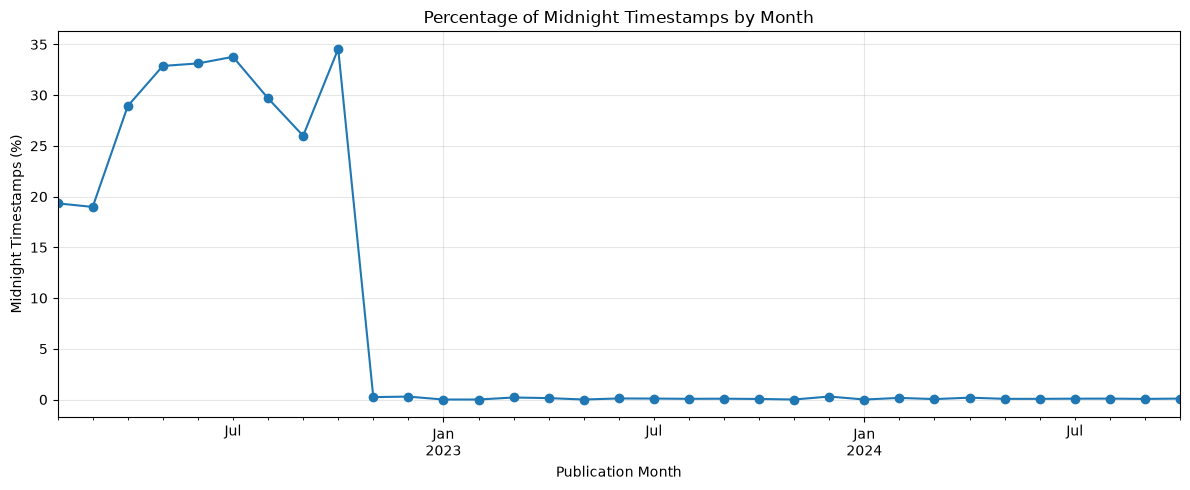

MONTHS WITH HIGHEST MIDNIGHT PERCENTAGE


timestamp
2022-10    34.558798
2022-07    33.772421
2022-06    33.123934
2022-05    32.877608
2022-08    29.683971
2022-04    28.926740
2022-09    25.991117
2022-02    19.334112
2022-03    18.978587
2023-12     0.295130
Freq: M, dtype: float64

In [87]:
import matplotlib.pyplot as plt

# Count midnight timestamps by publication month
midnight_by_month = (
    df_clean.loc[midnight_mask]
    .groupby(
        df_clean.loc[midnight_mask, "timestamp"]
        .dt.to_period("M")
    )
    .size()
)

# Count all Truths by publication month
truths_by_month = (
    df_clean.groupby(
        df_clean["timestamp"].dt.to_period("M")
    )
    .size()
)

# Percentage of midnight timestamps by month
midnight_percentage_by_month = (
    midnight_by_month
    .div(truths_by_month)
    .mul(100)
    .fillna(0)
)

plt.figure(figsize=(12, 5))

midnight_percentage_by_month.plot(
    kind="line",
    marker="o"
)

plt.title("Percentage of Midnight Timestamps by Month")
plt.xlabel("Publication Month")
plt.ylabel("Midnight Timestamps (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("MONTHS WITH HIGHEST MIDNIGHT PERCENTAGE")

display(
    midnight_percentage_by_month
    .sort_values(ascending=False)
    .head(10)
)